# Лабораторная работа 2. Регрессионный анализ

Датасет `powerconsumption.csv`: Данные состоят из 52 416 наблюдений потребления энергии за 10-минутный интервал. Каждое наблюдение описывается 9 столбцами признаков.

- Date Time: Time window of ten minutes.
- Temperature: Weather Temperature.
- Humidity: Weather Humidity.
- Wind Speed: Wind Speed.
- General Diffuse Flows: “Diffuse flow” is a catchall term to describe low-temperature (< 0.2° to ~ 100°C) fluids that slowly discharge through sulfide mounds, fractured lava flows, and assemblages of bacterial mats and macrofauna.
- Diffuse Flows
- Zone 1 Power Consumption
- Zone 2 Power Consumption
- Zone 3 Power Consumption

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import CubicSpline

plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.4})

In [2]:
df = pd.read_csv("powerconsumption.csv")
print (df.shape)
df.head(10)


(52416, 9)


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964
5,1/1/2017 0:50,5.853,76.9,0.081,0.059,0.108,26624.81013,17416.41337,18130.12048
6,1/1/2017 1:00,5.641,77.7,0.080,0.048,0.096,25998.98734,16993.31307,17945.06024
7,1/1/2017 1:10,5.496,78.2,0.085,0.055,0.093,25446.07595,16661.39818,17459.27711
8,1/1/2017 1:20,5.678,78.1,0.081,0.066,0.141,24777.72152,16227.35562,17025.54217
9,1/1/2017 1:30,5.491,77.3,0.082,0.062,0.111,24279.49367,15939.20973,16794.21687


In [3]:
df['Datetime'] = pd.to_datetime(df['Datetime'], format = '%m/%d/%Y %H:%M')
df = df.set_index('Datetime')
df = df.sort_index()

dif = df.index.to_series().diff().value_counts()
print (dif)

Datetime
0 days 00:10:00    52415
Name: count, dtype: int64


In [4]:
df_hour = df.resample('h').mean()
print (df_hour.shape)
df_hour.head()

(8736, 8)


,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Datetime,,,,,,,,
2017-01-01 00:00:00,6.196833,75.066667,0.081833,0.063500,0.098833,29197.974683,18026.747720,19252.048193
2017-01-01 01:00:00,5.548833,77.583333,0.082000,0.056833,0.112500,24657.215190,16078.419453,17042.891567
2017-01-01 02:00:00,5.054333,78.933333,0.082333,0.063000,0.129167,22083.037973,14330.699088,15676.144578
2017-01-01 03:00:00,5.004333,77.083333,0.082833,0.059833,0.141000,20811.139240,13219.452887,14883.855422
2017-01-01 04:00:00,5.097667,74.050000,0.082333,0.058000,0.122833,20475.949367,12921.580547,14317.108433


In [5]:
data = df_hour[['PowerConsumption_Zone1', 'Temperature', 'Humidity',
                'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows']].iloc[:360]
data.head()

,PowerConsumption_Zone1,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows
Datetime,,,,,,
2017-01-01 00:00:00,29197.974683,6.196833,75.066667,0.081833,0.063500,0.098833
2017-01-01 01:00:00,24657.215190,5.548833,77.583333,0.082000,0.056833,0.112500
2017-01-01 02:00:00,22083.037973,5.054333,78.933333,0.082333,0.063000,0.129167
2017-01-01 03:00:00,20811.139240,5.004333,77.083333,0.082833,0.059833,0.141000
2017-01-01 04:00:00,20475.949367,5.097667,74.050000,0.082333,0.058000,0.122833


Шаг 10 минут по всему файлу, пропусков во времени нет. Для прогнозирования усредняем до часа: 52416 десятиминутных значений превращаются в 8736 почасовых, суточная периодичность сохраняется, а шум уменьшается.

## 1. Выбор ряда и разбиение выборки

In [6]:
train_len = int(len(data) * 0.8)
train = data.iloc[:train_len]
test = data.iloc[train_len:]


In [7]:
from statsmodels.tsa.stattools import adfuller 

In [8]:
temp = adfuller(train['PowerConsumption_Zone1'])

stat = temp[0]
p_value = temp[1]
dic = temp[4]

print (stat)
print (p_value)
print (dic)



-10.18418712912958
6.574313414366093e-18
{'1%': np.float64(-3.4546223782586534), '5%': np.float64(-2.8722253212300277), '10%': np.float64(-2.5724638500216264)}


C:\Users\timur\AppData\Local\Temp\ipykernel_26108\1913386829.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  temp = adfuller(train['PowerConsumption_Zone1'])


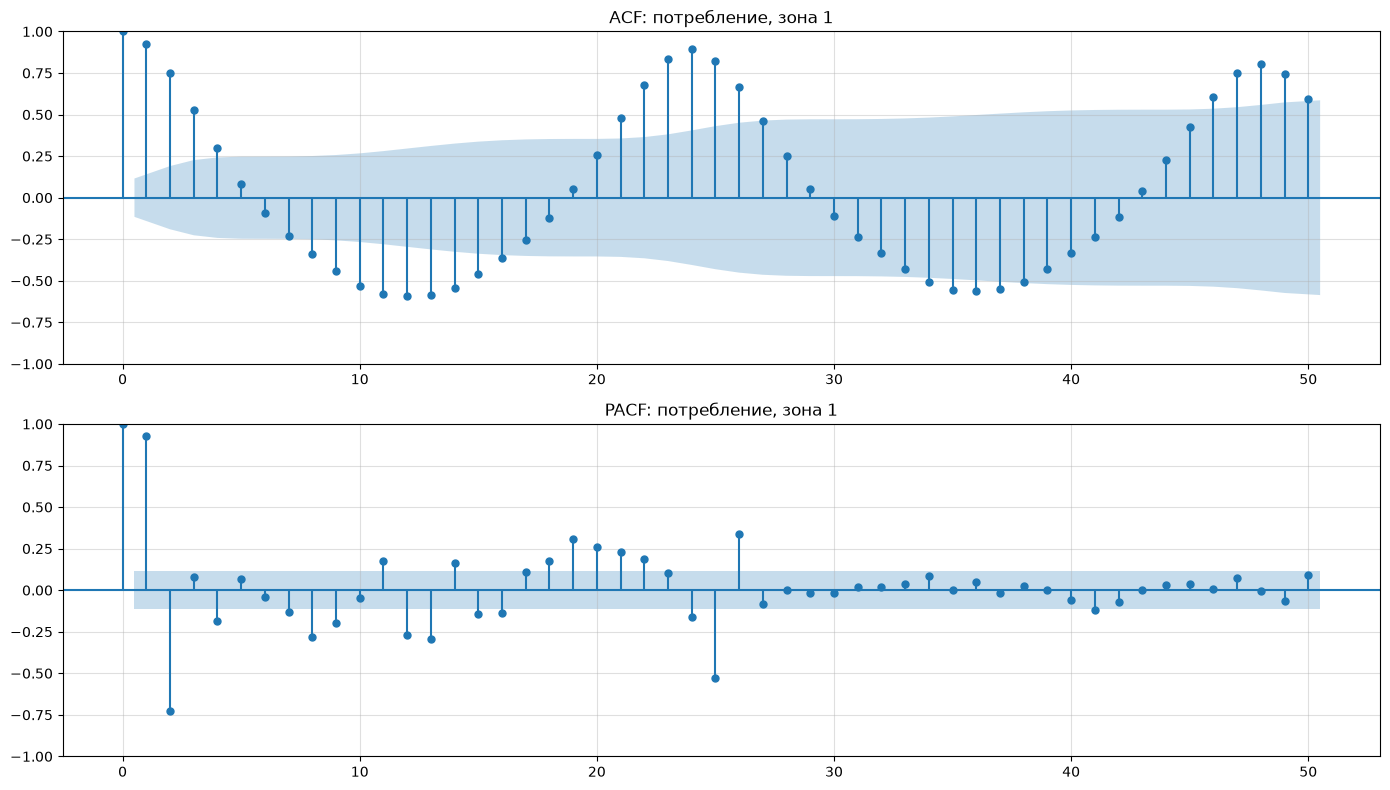

In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

series = train['PowerConsumption_Zone1'] 

fig, ax = plt.subplots(2, 1, figsize=(14, 8)) 

plot_acf(series, lags=50, ax=ax[0]) 
plot_pacf(series, lags=50, ax=ax[1])

ax[0].set_title('ACF: потребление, зона 1')
ax[1].set_title('PACF: потребление, зона 1')

plt.tight_layout()
plt.show()

In [10]:
from statsmodels.tsa.arima.model import ARIMA
model_1 = ARIMA(train['PowerConsumption_Zone1'], order = (2, 0, 1)).fit()
model_2 = ARIMA(train['PowerConsumption_Zone1'], order = (2, 0, 0)).fit()
print (model_1.aic)
print (model_2.aic)
print (model_1.summary())


5155.645946779188
5156.429546989423
                                 SARIMAX Results                                  
Dep. Variable:     PowerConsumption_Zone1   No. Observations:                  288
Model:                     ARIMA(2, 0, 1)   Log Likelihood               -2572.823
Date:                    Mon, 28 Sep 2026   AIC                           5155.646
Time:                            22:09:38   BIC                           5173.961
Sample:                        01-01-2017   HQIC                          5162.985
                             - 01-12-2017                                         
Covariance Type:                      opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.048e+04   1231.307     24.758      0.000    2.81e+04    3.29e+04
ar.L1          1.5128      0.081     18.739      0.000       1.

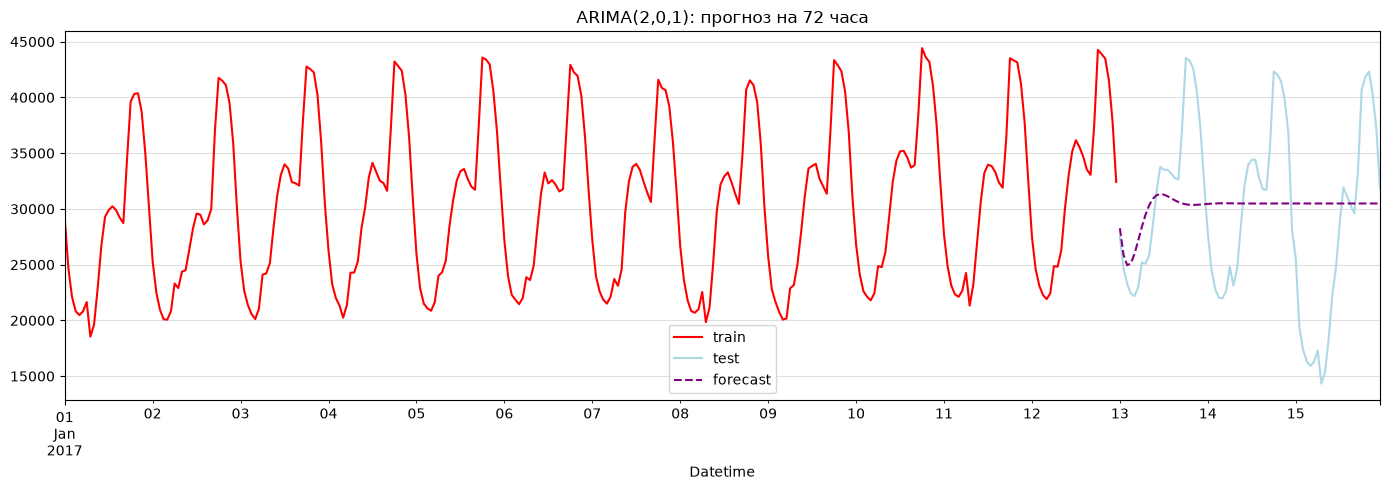

In [11]:
step = len(test)
result = model_1.forecast(steps = step)

fig, ax = plt.subplots(figsize=(14, 5)) 

train['PowerConsumption_Zone1'].plot(ax=ax, label = 'train', color = 'red')
test['PowerConsumption_Zone1'].plot(ax=ax, label = 'test', color = 'lightblue')
result.plot(ax=ax, label = 'forecast', color = 'purple', linestyle='--')


ax.set_title('ARIMA(2,0,1): прогноз на 72 часа')
ax.legend()
plt.tight_layout()
plt.show()


#### Вывод:
 ARIMA(2, 0, 1) подходит только для прогноза на несколько часов вперёд. На горизонте 72 часа она начинает прогнозировать средним, потому что без сезонной части не видит суточного цикла.

Добавляем сезонную часть с периодом 24 часа: на ACF лаг 24 даёт 0.9, суточный цикл выражен сильнее связи соседних часов.

In [12]:
model_3 = ARIMA(train['PowerConsumption_Zone1'], order = (2, 0, 1), seasonal_order = (1, 0, 1, 24)).fit(method_kwargs = {'maxiter': 500})
print (model_3.aic)

pred_arima = model_3.forecast(steps = len(test))

4579.487920805213


AIC падает с 5156 до 4579. Сезонная модель держит форму суточного цикла все 72 часа, дальше сравниваем с ней.

## 2. Прогноз методом k-NN

Признаки - 24 предыдущих значения ряда, отклик - следующее. Число соседей подбираем кросс-проверкой на тренировочной выборке, прогноз строим рекурсивно: предсказанное значение уходит в окно для следующего шага.

In [13]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

lags = 24
y_train = train['PowerConsumption_Zone1']
y_test = test['PowerConsumption_Zone1']

X_lag = np.column_stack([y_train.values[i:len(y_train) - lags + i] for i in range(lags)])
y_lag = y_train.values[lags:]

score = {k: -cross_val_score(KNeighborsRegressor(k), X_lag, y_lag, cv = TimeSeriesSplit(5),
                             scoring = 'neg_mean_absolute_error').mean() for k in range(1, 11)}
k_best = min(score, key = score.get)
print (k_best, round(score[k_best]))

1 771


In [14]:
knn = KNeighborsRegressor(k_best).fit(X_lag, y_lag)

history = list(y_train.values)
for _ in range(len(test)):
    history.append(knn.predict(np.array(history[-lags:]).reshape(1, -1))[0])

pred_knn = pd.Series(history[-len(test):], index = test.index)

Кросс-проверка на один шаг вперёд выбирает k = 1 с MAE 771. На 72 шагах рекурсии ошибка вырастает до 2088: прогноз повторяет самый похожий суточный профиль из обучающей части.

## 3. Однопараметрические модели

Предиктор - температура, её корреляция с потреблением 0.46, сильнее остальных погодных признаков. МНК считаем через нормальное уравнение $c = (A^TA)^{-1}A^Ty$, псевдообратную матрицу берём из `np.linalg.pinv`. Прогноз считаем на всём отрезке, чтобы на графике была видна и подгонка на тренировочной части.

In [15]:
def mnk_fit(X, y):
    A = np.column_stack([np.ones(len(X)), X])
    return np.linalg.pinv(A) @ y

def mnk_pred(c, X):
    return pd.Series(c[0] + np.asarray(X) @ c[1:], index = X.index)

f1 = ['Temperature']
c1 = mnk_fit(train[f1], y_train)
pred_mnk1 = mnk_pred(c1, data[f1])
print (c1)

[17548.8212297   1029.73508125]

In [16]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svr1 = make_pipeline(StandardScaler(), SVR(C = 100)).fit(train[f1], y_train)
pred_svr1 = pd.Series(svr1.predict(data[f1]), index = data.index)

МНК даёт $y = 17549 + 1030x$: каждый градус добавляет около 1030 кВт. SVR со стандартизацией и RBF-ядром описывает нелинейную связь и работает точнее.

## 4. Двухпараметрические модели

Второй параметр - влажность, $y = c_0 + c_1x_1 + c_2x_2$.

In [17]:
f2 = ['Temperature', 'Humidity']
c2 = mnk_fit(train[f2], y_train)
pred_mnk2 = mnk_pred(c2, data[f2])
print (c2)

svr2 = make_pipeline(StandardScaler(), SVR(C = 100)).fit(train[f2], y_train)
pred_svr2 = pd.Series(svr2.predict(data[f2]), index = data.index)

[7765.86929179 1219.0932275   102.04480517]


Влажность добавляет мало: на тренировочной части $R^2$ вырос с 0.244 до 0.253, на тесте МНК стал хуже. Коэффициент при влажности 102 против 1219 при температуре, а сама влажность связана с температурой обратно, поэтому второй признак почти дублирует первый.

## 5. Многопараметрические модели: Lasso и PLS

Берём все пять погодных признаков. Lasso со стандартизацией и подбором alpha по кросс-проверке, PLS на двух компонентах.

In [18]:
from sklearn.linear_model import LassoCV
from sklearn.cross_decomposition import PLSRegression

fm = list(data.columns[1:])

lasso = make_pipeline(StandardScaler(), LassoCV(cv = 5)).fit(train[fm], y_train)
pred_lasso = pd.Series(lasso.predict(data[fm]), index = data.index)
print (round(lasso[-1].alpha_), dict(zip(fm, lasso[-1].coef_.round(0))))

pls = PLSRegression(n_components = 2).fit(train[fm], y_train)
pred_pls = pd.Series(pls.predict(data[fm]).ravel(), index = data.index)

753 {'Temperature': np.float64(2742.0), 'Humidity': np.float64(-0.0), 'WindSpeed': np.float64(0.0), 'GeneralDiffuseFlows': np.float64(-0.0), 'DiffuseFlows': np.float64(-0.0)}


Lasso обнулила четыре коэффициента из пяти и оставила только температуру. PLS собирает те же признаки в две компоненты и приходит к тому же результату: погодные данные объясняют около 10% дисперсии потребления.

## 6. Графики

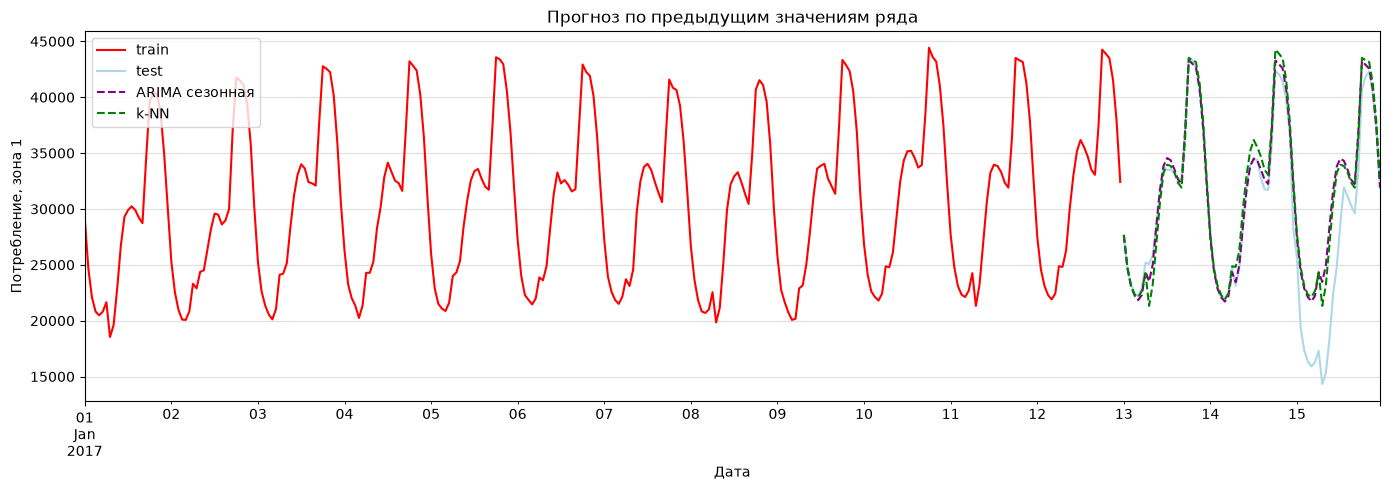

In [19]:
fig, ax = plt.subplots(figsize = (14, 5))

y_train.plot(ax = ax, label = 'train', color = 'red')
y_test.plot(ax = ax, label = 'test', color = 'lightblue')
pred_arima.plot(ax = ax, label = 'ARIMA сезонная', color = 'purple', linestyle = '--')
pred_knn.plot(ax = ax, label = 'k-NN', color = 'green', linestyle = '--')

ax.set_xlabel('Дата')
ax.set_ylabel('Потребление, зона 1')
ax.set_title('Прогноз по предыдущим значениям ряда')
ax.legend()
plt.tight_layout()
plt.show()

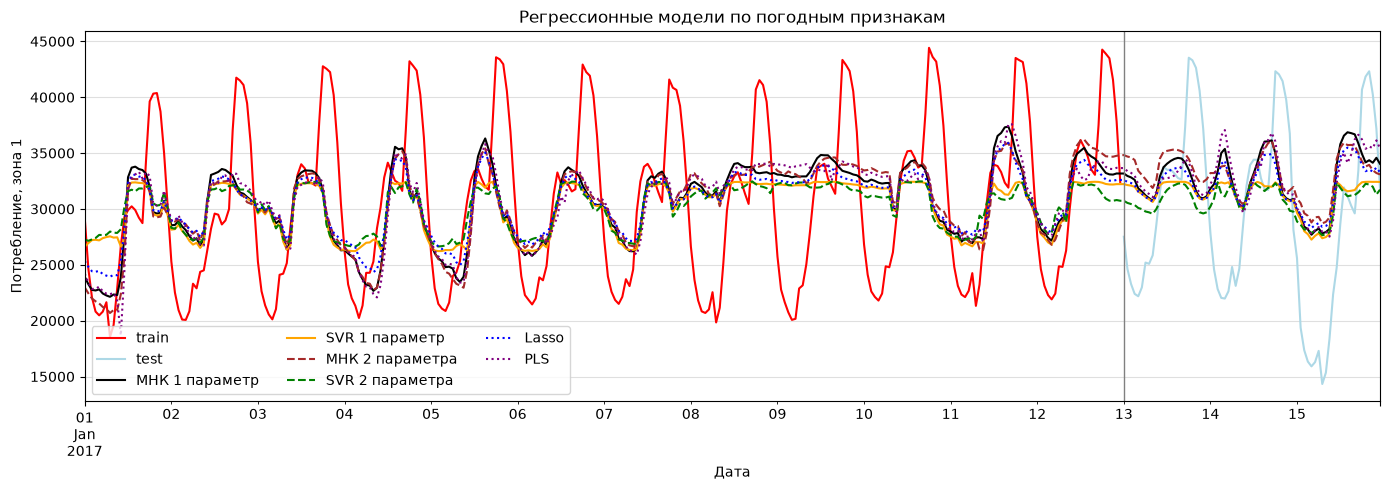

In [20]:
fig, ax = plt.subplots(figsize = (14, 5))

y_train.plot(ax = ax, label = 'train', color = 'red')
y_test.plot(ax = ax, label = 'test', color = 'lightblue')
pred_mnk1.plot(ax = ax, label = 'МНК 1 параметр', color = 'black')
pred_svr1.plot(ax = ax, label = 'SVR 1 параметр', color = 'orange')
pred_mnk2.plot(ax = ax, label = 'МНК 2 параметра', color = 'brown', linestyle = '--')
pred_svr2.plot(ax = ax, label = 'SVR 2 параметра', color = 'green', linestyle = '--')
pred_lasso.plot(ax = ax, label = 'Lasso', color = 'blue', linestyle = ':')
pred_pls.plot(ax = ax, label = 'PLS', color = 'purple', linestyle = ':')

ax.axvline(test.index[0], color = 'gray', linewidth = 1)
ax.set_xlabel('Дата')
ax.set_ylabel('Потребление, зона 1')
ax.set_title('Регрессионные модели по погодным признакам')
ax.legend(ncol = 3, loc = 'lower left')
plt.tight_layout()
plt.show()

Обе модели повторяют суточные волны. Сезонная ARIMA сглаживает вершины (34-35 тысяч против 43-44 фактических), k-NN попадает в пики точно - отсюда его меньшая RMSE. Общая ошибка обеих моделей одна: провал ночью 15 января до 14 300, которого в обучающей части не было ни разу.

Погодные модели идут узкой полосой 27-37 тысяч около среднего. Суточный размах потребления им недоступен: температура за сутки меняется плавно и задаёт только медленный тренд.

## 7. Сравнение точности

In [21]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

preds = {'ARIMA(2,0,1)': result, 'ARIMA сезонная': pred_arima, 'k-NN': pred_knn,
         'МНК 1': pred_mnk1, 'SVR 1': pred_svr1, 'МНК 2': pred_mnk2, 'SVR 2': pred_svr2,
         'Lasso': pred_lasso, 'PLS': pred_pls}

metrics = pd.DataFrame({name: {'MAE': mean_absolute_error(y_test, p.loc[test.index]),
                               'RMSE': root_mean_squared_error(y_test, p.loc[test.index]),
                               'R2': r2_score(y_test, p.loc[test.index])}
                        for name, p in preds.items()}).T.round(3)
metrics

,MAE,RMSE,R2
"ARIMA(2,0,1)",6184.680,7666.537,0.051
ARIMA сезонная,1829.593,3255.313,0.829
k-NN,2088.101,3140.145,0.841
МНК 1,6452.000,7502.582,0.091
SVR 1,5983.901,7192.792,0.165
МНК 2,6756.653,7797.373,0.019
SVR 2,5896.456,7163.760,0.172
Lasso,6335.457,7474.512,0.098
PLS,6307.786,7464.149,0.101


#### Выводы

Разрыв идёт не между методами, а между источниками информации. Модели на предыдущих значениях ряда дают MAE 1830-2090 при среднем потреблении 29 700, то есть 6-7% ошибки, и R² выше 0.82. Модели на погодных признаках дают MAE 5900–6800 и R² от 0.02 до 0.17, почти на уровне прогноза средним.

Причина в суточном цикле. За 72 часа теста потребление несколько раз проходит путь от 14 300 до 43 500, а температура меняется плавно и объясняет только медленный тренд. Без сезонной части этого не видит и ARIMA: (2,0,1) сходится к среднему после нескольких часов и получает R² 0.051, та же модель с сезонной частью (1,0,1,24) - 0.829.

Второй параметр модель не улучшил. У МНК R² на тесте упал с 0.091 до 0.019: влажность коррелирует с температурой, и лишний коэффициент подгоняется под тренировочную выборку. Lasso подтверждает это независимо - из пяти признаков осталась одна температура, PLS с двумя компонентами дала те же 0.101. Из погодных моделей лучшая SVR на двух параметрах, R² 0.172: RBF-ядро описывает нелинейную связь, а эпсилон-полоса гасит выбросы.

По MAE и RMSE порядок моделей почти совпадает, расходятся только два лидера: у k-NN RMSE ниже (3140 против 3255), а MAE выше (2088 против 1830). k-NN точнее берёт редкие большие пики, сезонная ARIMA ровнее держит остальные часы.